# Crabtree Creek: flood-peak forecasting

Johann Alexander Vera Mercado. Five years of five-minute USGS observations; forecast horizons of 1–6 hours.

This version predicts water-surface elevation in feet NAVD88, not discharge. It preserves peaks and evaluates separate chronological periods. Read README.md before interpreting warnings. A separate Spanish guide is available in GUIA_ES.md.

## Saved benchmark results — visible without running code

These are archived v0.1 results from `metrics.csv`, not a new training run. The code cells below remain unexecuted. All errors are in feet; persistence predicts the current elevation.

| Horizon | Persistence MAE | Model MAE | Persistence high-water MAE | Model high-water MAE |
|---|---:|---:|---:|---:|
| 1 h | 0.0284 | 0.0201 | 0.3238 | 0.1907 |
| 2 h | 0.0525 | 0.0466 | 0.6010 | 0.4464 |
| 3 h | 0.0732 | 0.0706 | 0.8076 | 0.6217 |
| 4 h | 0.0914 | 0.0951 | 0.9864 | 0.7905 |
| 5 h | 0.1081 | 0.1118 | 1.1456 | 0.9443 |
| 6 h | 0.1231 | 0.1306 | 1.2982 | 1.0663 |

### Interpretation

The gradient boosting benchmark reduces high-water MAE at all six horizons. Overall MAE improves at 1–3 hours and worsens at 4–6 hours; overall RMSE worsens at 3–6 hours. This supports further research, not an operational warning claim. Neural models have not been trained in v0.1.

### Largest test event

The figure aligns successive rolling forecasts by valid time. It is not a single forecast trajectory issued six hours before the event.

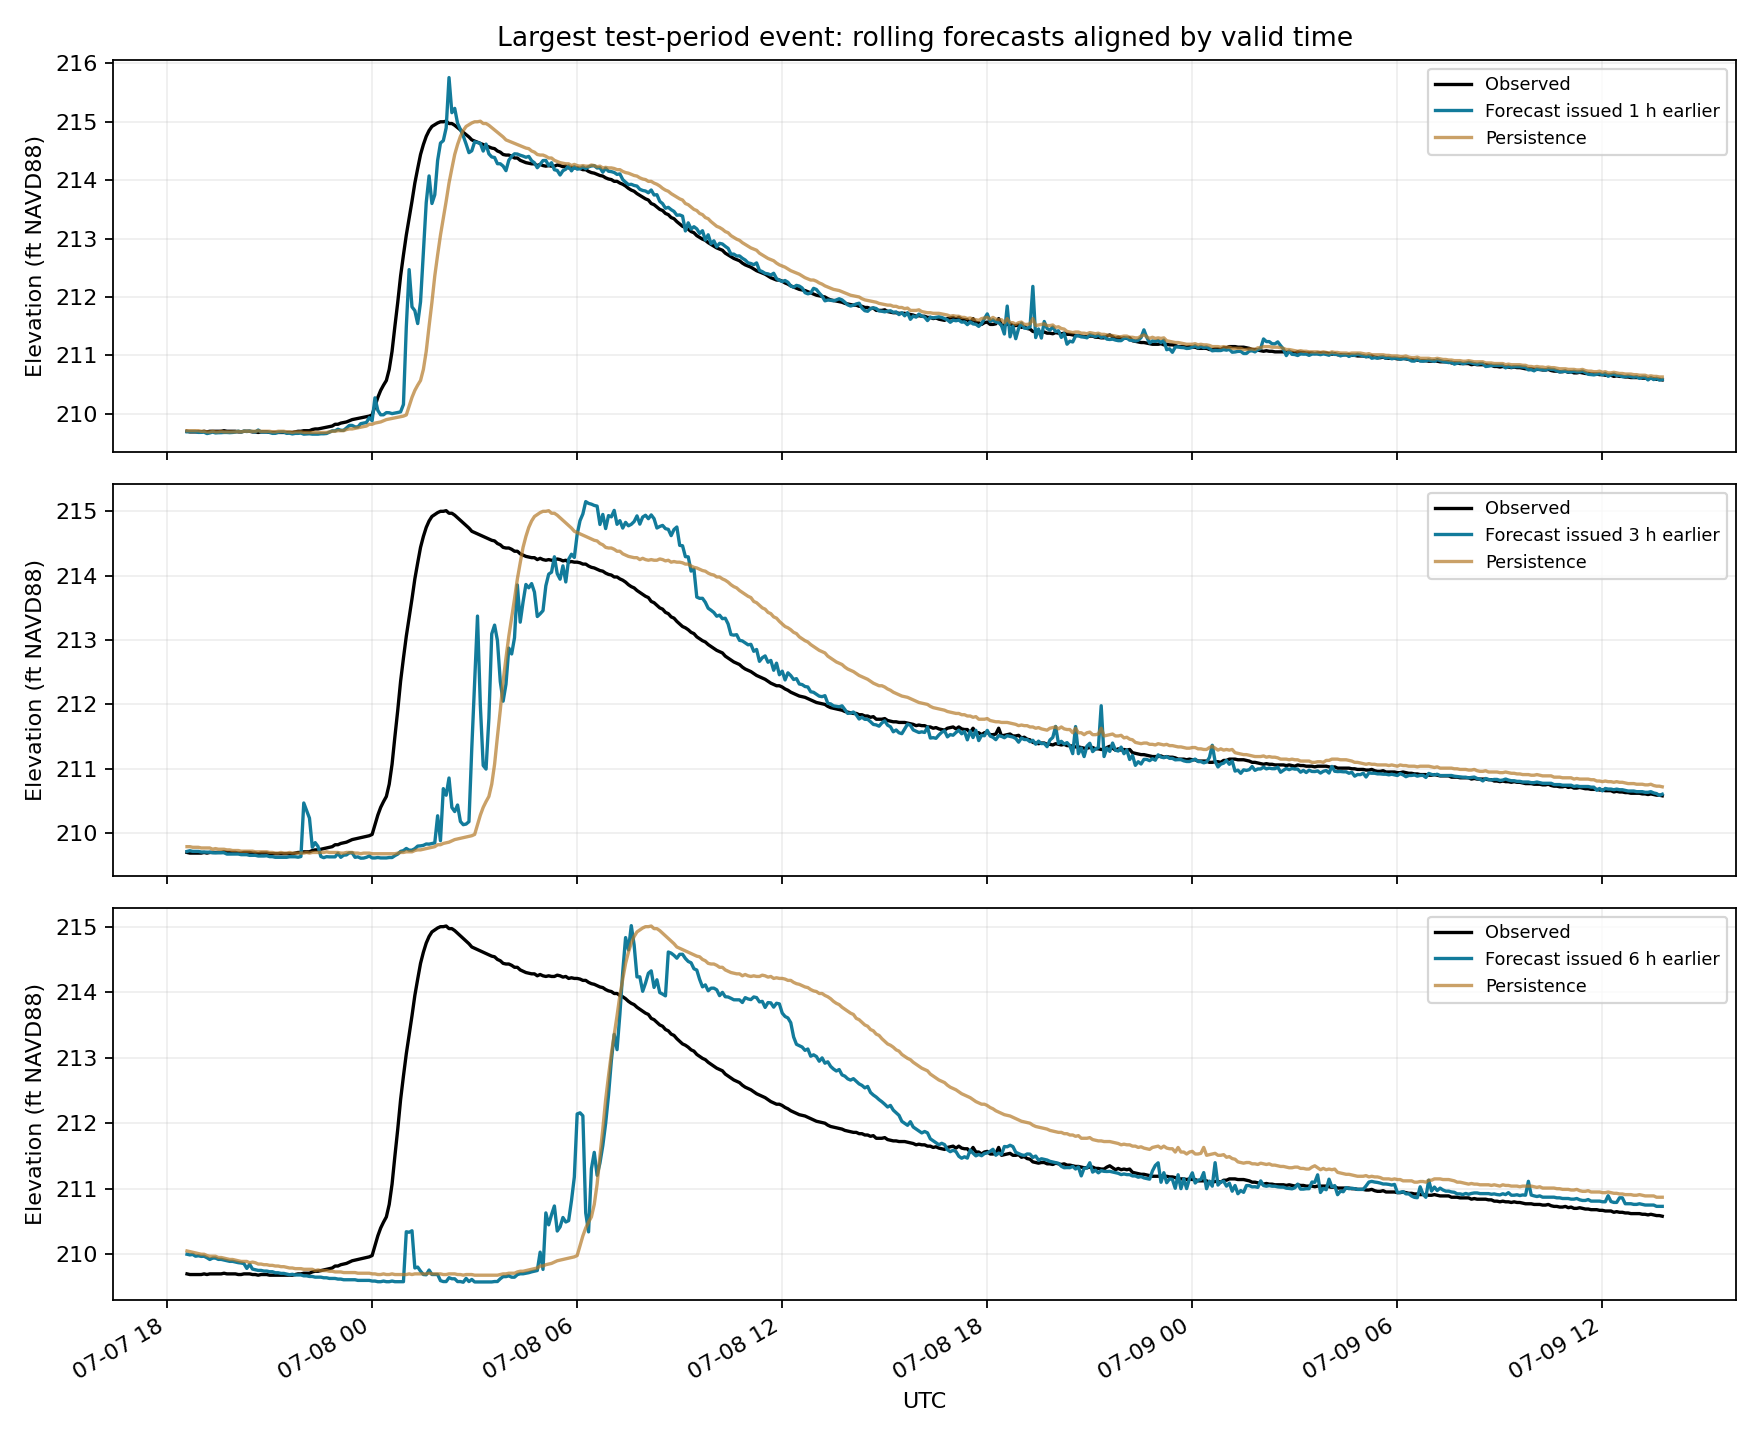

The high-water threshold is a training-derived research threshold, not an official flood level. Correlated five-minute predictions are not independent event detections. See the README for validation limits and precipitation assumptions.

## 1. Setup
Run from the project directory. In Colab, upload and extract the complete ZIP snapshot or clone the public repository. These commands do not require Google Drive access.

In [ ]:
!pip install -r requirements.txt


In [ ]:
!python download_data.py
!python -m unittest test_integrity.py


## 2. Inspect data without removing peaks
Missing values are preserved. Timestamps are converted to UTC and overlapping records are deduplicated. Missing rain is never replaced with zero.

In [ ]:
from forecast import load, features
df, audit = load()
print(audit)
df[["level_ft", "rain_in"]].plot(subplots=True, figsize=(12, 6))


## 3. Training
Training ends in October 2024; validation covers October 2024–2025; testing begins in October 2025. Targets crossing split boundaries are excluded. High-water targets receive weight 4. Hyperparameters are selected on validation, not test data.

In [ ]:
!OMP_NUM_THREADS=2 python forecast.py
!python evaluate_events.py


In [ ]:
import pandas as pd
from IPython.display import display, Image
display(pd.read_csv("results/metrics.csv"))
display(pd.read_csv("results/threshold_metrics.csv"))
display(Image("results/largest_test_event.png"))


## 4. Hydrologic interpretation
Review peak magnitude, timing and missed events. The training threshold is statistical, not operational. The plot shows successive forecasts aligned by valid time, not a single-issue forecast trajectory. At 4–6 hours, the model does not outperform persistence on overall error.

Confirm the rainfall sensor reporting convention before interpreting sums as physical accumulations.

## 5. Optional neural models
Corrected code to continue the original LSTM/GRU/BiLSTM comparison; NOT trained in this initial run. Requires TensorFlow. Align eligible timestamps before comparing models.

In [ ]:
# Optional execution:
# !pip install -r requirements-neural.txt
# !python neural_models.py --kind gru --epochs 30
